# Bước 3 — Dataset, transforms, DataLoader và metric

Notebook minh họa được đưa lên Git để các thành viên chạy chung. Logic nằm trong module Python; notebook giải thích và xem hình. Chọn kernel đã cài `requirements-training.txt`, rồi **Restart Kernel → Run All**.

Đầu vào: dữ liệu và split đã chốt ở bước 2. Không tải dữ liệu, không chia lại split, không train mô hình. Chỉ đọc train/validation; test và ClinicDB để đánh giá cuối. Không bắt buộc GPU để chạy notebook này.

## 1. Tìm gốc repo và đọc cấu hình

Không dùng đường dẫn ổ đĩa của một máy. `configs/unet.yaml` chứa preprocessing và thông số khởi đầu M1; các mục training chỉ là kế hoạch cho bước 4, chưa có vòng train hoạt động.


In [1]:
import sys
from pathlib import Path

start = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (start, *start.parents)
                     if (p / "src/datasets").is_dir() and (p / "README.md").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Mở notebook trong cây thư mục repo.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import torch
from PIL import Image
from IPython.display import display
from src.utils import load_config, seed_everything
from src.datasets.dataset import create_dataloaders
from src.datasets.preview import save_transform_preview
from src.metrics import binary_metrics, metrics_at_original_size

config = load_config(PROJECT_ROOT / "configs/unet.yaml")
print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Cấu hình input:", config["data"]["image_size"])


Python: d:\anaconda\envs\data_processing\python.exe
PyTorch: 2.9.1+cu126
Cấu hình input: [256, 256]


## 2. Đọc một batch từ split cố định

Dataset đọc đúng ID, ảnh RGB và mask grayscale. Mask nhị phân hóa >127; resize mask bằng nearest-neighbor và ảnh bằng bilinear về 256×256. Chuyển ảnh thành tensor float trong [0,1], rồi normalize ImageNet; mask vẫn 0/1, không normalize.

Train shuffle và augmentation. Validation không shuffle/augmentation; giữ thêm mask gốc trong **list** vì kích thước các ảnh khác nhau, không thể stack mask gốc thành một tensor chung. `original_size` ghi theo (cao, rộng).

Mặc định num_workers=0 để chạy được cả Windows/notebook. Đừng tự đổi seed chia tập khi thử seed huấn luyện.


In [2]:
loaders = create_dataloaders(PROJECT_ROOT, config)
train_batch = next(iter(loaders["train"]))
val_batch = next(iter(loaders["val"]))
print("Số mẫu:", {name: len(loader.dataset) for name, loader in loaders.items()})
print("Ảnh train:", tuple(train_batch["image"].shape), train_batch["image"].dtype)
print("Mask train:", tuple(train_batch["mask"].shape), train_batch["mask"].unique().tolist())
print("ID đầu:", train_batch["image_id"][0])
print("Kích thước mask gốc validation:", [tuple(m.shape) for m in val_batch["original_mask"]])
assert torch.isfinite(train_batch["image"]).all()
assert set(train_batch["mask"].unique().tolist()) <= {0, 1}


Số mẫu: {'train': 700, 'val': 150}
Ảnh train: (8, 3, 256, 256) torch.float32
Mask train: (8, 1, 256, 256) [0.0, 1.0]
ID đầu: Kvasir-SEG/cju8clorgsuwn08714toqb7v6.jpg
Kích thước mask gốc validation: [(1, 528, 622), (1, 1019, 1214), (1, 530, 611), (1, 546, 609), (1, 547, 620), (1, 531, 622), (1, 531, 480), (1, 529, 622)]


## 3. Xem cùng một ảnh trước và sau transforms

Hình có bốn cột: ảnh gốc, overlay nhãn gốc, resize cố định của validation, và augmentation của train. Hình minh họa chỉ lấy ảnh **train**; cột resize mô phỏng xử lý đánh giá trên chính ảnh đó.

Lật ngang, lật dọc (mỗi phép p=0.5) và xoay góc 0/90/180/270° dùng cùng lựa chọn cho ảnh và mask. Khi hiển thị, đảo normalization về RGB. Tất cả overlay dùng mask thật, không phải dự đoán mô hình. Dữ liệu gốc không bị ghi đè, bản sau xử lý chỉ ở RAM; chỉ hình minh họa được lưu.


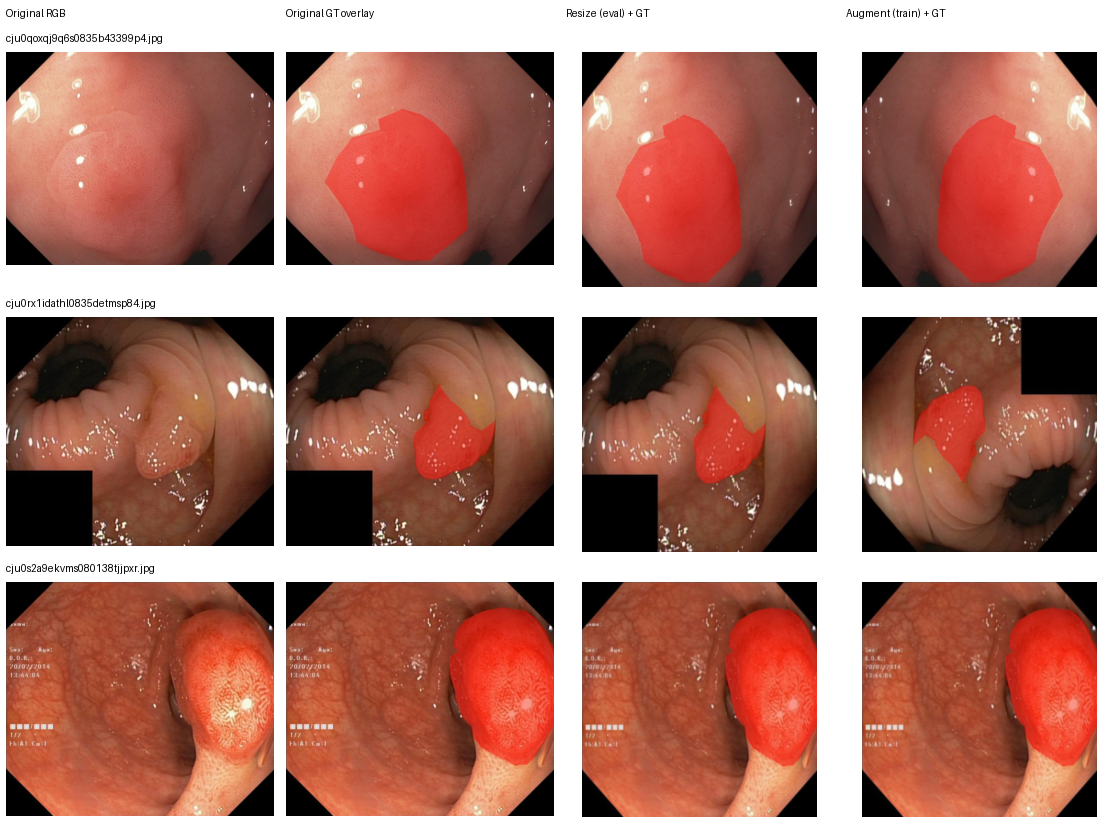

Hình: results\figures\step3_transforms.png


In [3]:
seed_everything(config["seed"])
figure_path = save_transform_preview(
    loaders["train"].dataset, PROJECT_ROOT / "results/figures/step3_transforms.png")
with Image.open(figure_path) as image:
    display(image.copy())
print("Hình:", figure_path.relative_to(PROJECT_ROOT))


## 4. Dice/IoU — kiểm tra bằng ví dụ biết trước

Metric tính riêng từng ảnh, sau đó lấy trung bình các ảnh. Hai mask rỗng cho Dice/IoU=1; chỉ một mask rỗng cho 0. Precision/Recall bằng 0 khi mẫu số không xác định. Đây là metric nhị phân, khác soft Dice dùng làm loss.

Ví dụ dưới: ảnh đầu có TP=1, số pixel dương dự đoán=2 và nhãn=2, nên Dice=0.5, IoU=1/3. Ảnh thứ hai cả hai rỗng nên Dice/IoU=1. **Đây là kiểm tra công thức, chưa phải kết quả của mô hình.**


In [4]:
truth = torch.tensor([[[1., 1., 0.]], [[0., 0., 0.]]])
prediction = torch.tensor([[[1., 0., 1.]], [[0., 0., 0.]]])
scores = binary_metrics(prediction, truth, from_logits=False)
print({name: value.tolist() for name, value in scores.items()})
print("Dice trung bình hai ảnh:", scores["dice"].mean().item())
assert torch.allclose(scores["dice"], torch.tensor([0.5, 1.]))


{'dice': [0.5, 1.0], 'iou': [0.3333333432674408, 1.0], 'precision': [0.5, 0.0], 'recall': [0.5, 0.0]}
Dice trung bình hai ảnh: 0.75


## 5. Đường đánh giá ở kích thước gốc

Khi có model, đầu ra là logits [B,1,256,256]. `metrics_at_original_size` resize **logits** bằng bilinear align_corners=False về kích thước gốc của từng ảnh, sau đó sigmoid và lấy ngưỡng 0.5. So sánh với mask gốc, không resize mask thật để lấy điểm chính.

Đoạn dưới dùng logits nền giả chỉ để kiểm tra luồng và shape; không công bố thành hiệu năng mô hình. Khi tổng hợp nhiều batch, cộng điểm từng ảnh và chia tổng số ảnh, không lấy trung bình các batch mà bỏ qua batch cuối có ít ảnh hơn.


In [5]:
dummy_logits = torch.full_like(val_batch["mask"], -20)
original_scores = metrics_at_original_size(
    dummy_logits, val_batch["original_mask"], threshold=config["evaluation"]["threshold"])
print("Số điểm metric từng ảnh:", {name: value.numel() for name, value in original_scores.items()})
assert original_scores["dice"].numel() == len(val_batch["image_id"])


Số điểm metric từng ảnh: {'dice': 8, 'iou': 8, 'precision': 8, 'recall': 8}


## Tiếp theo

Từ terminal có thể kiểm tra lại bước 3 bằng `python -m scripts.preview_data --project-root .`; kết quả lưu ở results/tables/step3_check.json.

Bước 4 sẽ viết U-Net tự cài, BCE+Dice, vòng train/validation và học thử 4–8 ảnh. Notebook hiện tại không tạo checkpoint hoặc chạy train.
